# 7. Benchmarking computacional

Este capítulo responde P1: ¿a partir de qué volumen PySpark supera a scikit-learn en tiempo de entrenamiento sin degradar la
calidad? Cada punto corrió en un proceso nuevo, con el equipo dedicado. Se separan lectura, preprocesamiento,
entrenamiento y predicción.

**Hardware:** Intel Core i5-13420H (8 núcleos físicos, 4 P y 4 E, 12 hilos), 31,7 GB de RAM y SSD, en Windows 11. Spark corre en
modo local con 14 GB de heap. Ese modo no tiene red ni fallos de nodo: es el mejor caso para Spark en coordinación, y el
peor en memoria, porque driver y ejecutor son el mismo proceso.

**Trabajo fijo por motor.** LR: hash12 y 20 pasadas. MLP: frecuencia (`d = 27`), una capa de 50. El optimizador difiere: SGD o
Adam en scikit-learn y l-bfgs en Spark. Por eso cada punto reporta también su AUC.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from ctr.plots import C, style, es, miles
from ctr.config import RES
from ctr.monitor import read_jsonl
from IPython.display import display
style()
pd.set_option("display.max_columns", 30)
B = pd.DataFrame(read_jsonl(RES / "bench" / "points.jsonl"))
ENG = {"sk": ("scikit-learn", C["azul"]), "spark": ("PySpark", C["naranja"])}

## 7.1 Lectura

In [2]:
I = pd.DataFrame(read_jsonl(RES / "bench" / "ingest.jsonl")).drop_duplicates(["step", "engine"], keep="last")
L = {"read_csv_count": "Contar filas en CSV", "csv_to_parquet": "CSV a Parquet por día", "csv_transform_noop": "Misma transformación a noop", "agg_csv": "Agregado sobre CSV", "agg_parquet": "Agregado sobre Parquet"}
i = I[I.step.isin(L)].assign(Paso=lambda d: d.step.map(L)).pivot(index="Paso", columns="engine", values="sec").round(2)
i.loc[list(L.values())]

engine,duckdb,polars,spark
Paso,,,
Contar filas en CSV,NaN,NaN,7.16
CSV a Parquet por día,286.63,NaN,NaN
Misma transformación a noop,NaN,NaN,57.97
Agregado sobre CSV,5.12,8.31,22.68
Agregado sobre Parquet,0.10,0.27,6.51


La memoria de esa primera tabla no se reporta porque quedó contaminada por el proceso anterior. Spark gana a pandas por mucho, pero
DuckDB y Polars ganan a Spark en una sola máquina: 0,1 y 0,3 segundos frente a 6,5 s sobre Parquet.

## 7.2 Punto de cruce

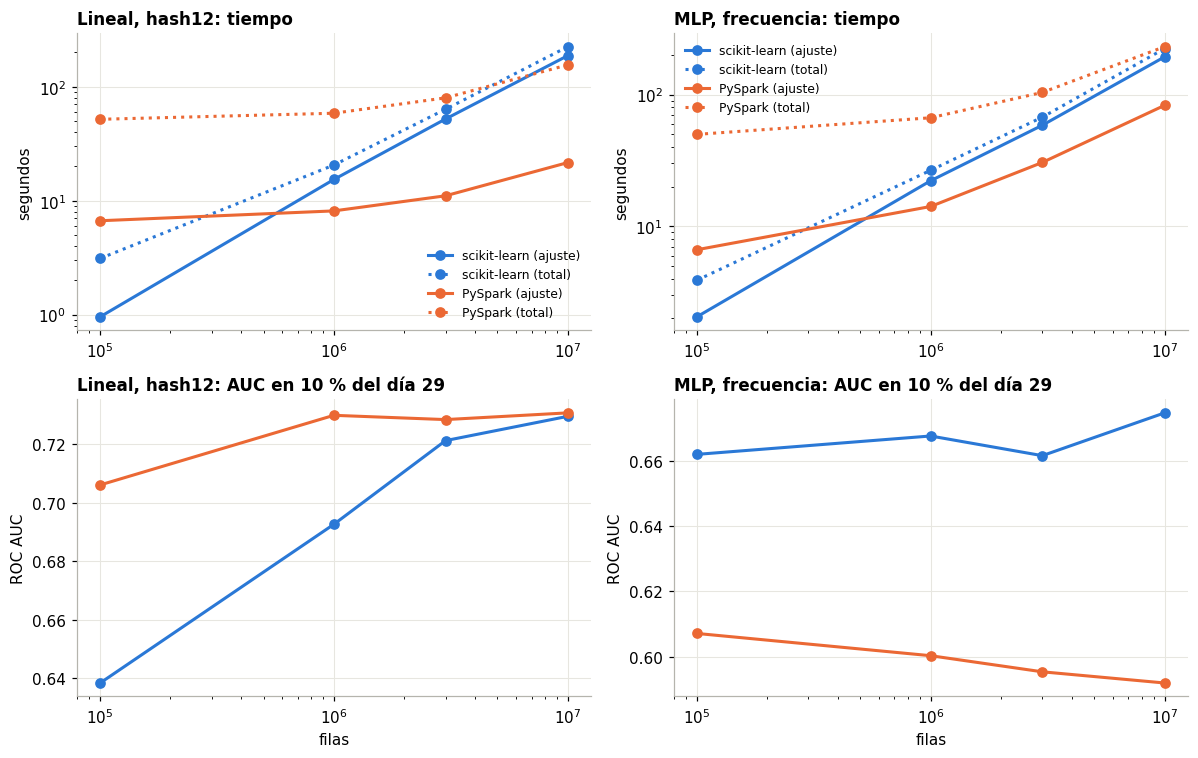

,Modelo,Medida,Exponente sklearn,Exponente Spark,Cruce estimado (filas)
0,"Lineal, hash12",solo ajuste,1.15,0.24,680090.74
1,"Lineal, hash12",lectura + prep. + ajuste,0.92,0.22,4944475.11
2,"MLP, frecuencia",solo ajuste,0.98,0.54,853661.95
3,"MLP, frecuencia",lectura + prep. + ajuste,0.87,0.32,7716367.83


In [3]:
c = B[B.exp == "cruce"].copy()
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
res = []
for j, (m, t) in enumerate([("lr", "Lineal, hash12"), ("mlp", "MLP, frecuencia")]):
    for e, (nom, co) in ENG.items():
        d = c[(c.engine == e) & (c.model == m)].sort_values("n")
        ax[0, j].plot(d.n, d.fit, marker="o", color=co, label=nom + " (ajuste)")
        ax[0, j].plot(d.n, d.read + d.prep + d.fit, marker="o", ls=":", color=co, label=nom + " (total)")
        ax[1, j].plot(d.n, d.auc, marker="o", color=co, label=nom)
    ax[0, j].set_xscale("log"); ax[0, j].set_yscale("log"); ax[0, j].set(title=f"{t}: tiempo", ylabel="segundos"); ax[0, j].legend(fontsize=8)
    ax[1, j].set_xscale("log"); ax[1, j].set(title=f"{t}: AUC en 10 % del día 29", xlabel="filas", ylabel="ROC AUC")
    a, b = c[(c.engine == "sk") & (c.model == m)].sort_values("n"), c[(c.engine == "spark") & (c.model == m)].sort_values("n")
    # ajuste log-log de cada curva y cruce analítico
    for col, nom in [("fit", "solo ajuste"), ("tot", "lectura + prep. + ajuste")]:
        ya = a.fit if col == "fit" else a.read + a.prep + a.fit
        yb = b.fit if col == "fit" else b.read + b.prep + b.fit
        pa, pb = np.polyfit(np.log(a.n), np.log(ya), 1), np.polyfit(np.log(b.n), np.log(yb), 1)
        x = np.exp((pb[1] - pa[1]) / (pa[0] - pb[0])) if pa[0] != pb[0] else np.nan
        res.append(dict(Modelo=t, Medida=nom, **{"Exponente sklearn": pa[0], "Exponente Spark": pb[0], "Cruce estimado (filas)": x}))
plt.tight_layout(); plt.show()
pd.DataFrame(res).round(2)

In [4]:
c.assign(motor=c.engine.map(lambda e: ENG[e][0]))[["motor", "model", "n", "read", "prep", "fit", "pred", "gb", "rows_s_fit", "auc"]].sort_values(["model", "motor", "n"]).round(3).reset_index(drop=True)

,motor,model,n,read,prep,fit,pred,gb,rows_s_fit,auc
0,PySpark,lr,100110,6.478,38.668,6.668,5.152,8.418,15013.557,0.706
1,PySpark,lr,999123,6.325,44.113,8.135,5.511,8.575,122814.000,0.730
2,PySpark,lr,3000326,5.738,63.150,11.042,5.402,9.580,271729.798,0.728
3,PySpark,lr,10003138,5.469,128.610,21.612,6.937,14.967,462843.546,0.731
4,scikit-learn,lr,100110,0.785,1.373,0.957,0.061,2.011,104596.456,0.638
5,scikit-learn,lr,999123,0.724,4.477,15.352,0.085,3.183,65080.449,0.693
6,scikit-learn,lr,3000326,0.835,10.520,52.147,0.047,6.786,57535.796,0.721
7,scikit-learn,lr,10003138,1.131,35.953,187.751,0.066,17.242,53278.784,0.730
8,PySpark,mlp,100110,6.263,36.920,6.638,4.671,7.950,15081.707,0.607
9,PySpark,mlp,999123,6.182,46.284,14.132,4.069,8.368,70698.759,0.600


**Control de hilos.** scikit-learn corre con un hilo de BLAS. Con 8 hilos, el MLP es más lento, porque sus matrices de 27 x 50
son demasiado pequeñas para repartir:

In [5]:
x = B[B.exp.isin(["cruce", "blas8"]) & (B.engine == "sk") & (B.model == "mlp") & (B.n > 2e6)]
x.assign(hilos=np.where(x.exp == "blas8", 8, 1)).pivot(index="n", columns="hilos", values="fit").round(1).rename_axis(columns="Hilos BLAS: ajuste (s)")

Hilos BLAS: ajuste (s),1,8
n,,
3000326,58.4,94.1
10003138,193.1,305.8


**Respuesta a P1.**

- **Modelo lineal: Spark gana desde unos 5 millones de filas sin perder calidad.** En el ajuste solo, el cruce estimado está en
  unas 680 mil filas. Contando lectura y preprocesamiento sube a unos 4,9 millones, porque Spark arrastra unos 45 s fijos de
  preparación. Con 10 millones, Spark tarda 156 s en total frente a 225 s, y su ajuste es 8,7 veces más rápido (21,6 s frente a
  187,8 s). El AUC es igual (0,731 frente a 0,730), y con menos filas Spark es mejor: con 20 pasadas, l-bfgs converge y SGD todavía
  no.
- **MLP: no hay volumen en el que Spark gane sin perder calidad.** Ajusta más rápido desde unas 850 mil filas. En tiempo total no
  gana ni con 10 millones (231 s frente a 223 s): la recta log-log extrapola un cruce cerca de 7,7 millones, pero el punto medido
  lo contradice. Además, su AUC (0,59 a 0,61) queda 0,07 a 0,08 por debajo del de scikit-learn (0,66 a 0,67) en todos los
  volúmenes. Con frecuencia y sigmoide, 20 iteraciones de l-bfgs no alcanzan lo que logran 10 épocas de Adam en minilotes.
- **Los exponentes explican el cruce.** En scikit-learn el tiempo crece casi lineal con `n` (exponente de 0,9 a 1,15). En Spark
  crece con exponente de 0,2 a 0,5: con pocas filas domina un costo fijo (arranque de la JVM, planificación de tareas y las 23
  agregaciones del preprocesamiento).
- **En predicción, scikit-learn gana siempre.** Puntúa de 2 a 8 millones de filas por segundo, frente a 55 a 95 mil de Spark, que
  incluye transformar el pipeline y materializar el resultado.
- **Memoria.** Spark parte de unos 8 GB, que son el heap reservado de la JVM. scikit-learn crece con `n` y lo alcanza con 10
  millones de filas (17 GB frente a 15 GB).

Los optimizadores difieren entre motores (SGD o Adam frente a l-bfgs), así que el cruce compara implementaciones completas, no
solo motores. Por eso cada punto reporta su AUC.

## 7.3 Escalamiento fuerte, aceleración y ley de Amdahl

Con 2 millones de filas fijas y 1, 2, 4 y 8 núcleos: $S(p) = T_1 / T_p$ y $E(p) = S(p) / p$. La ley de Amdahl es
$S(p) = 1 / (f + (1 - f) / p)$, donde $f$ es la fracción secuencial.

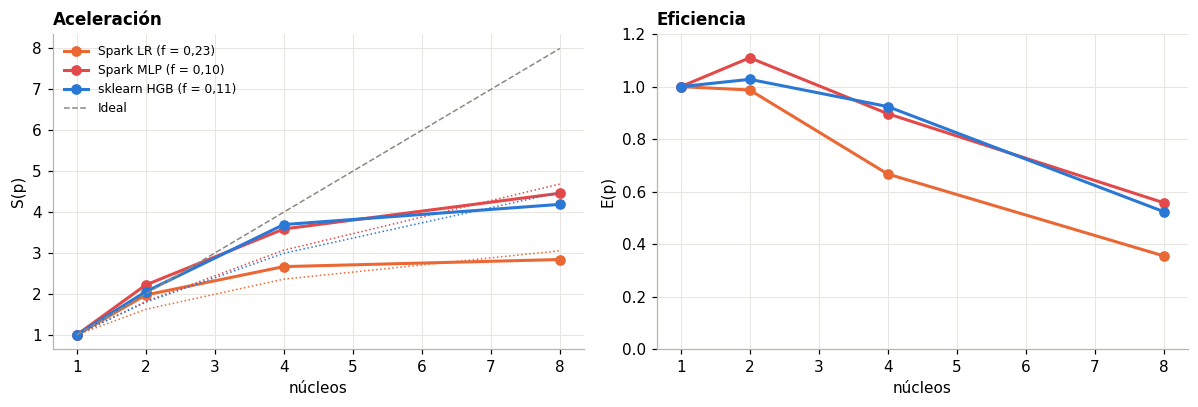

,f,S(1),S(2),S(4),S(8),E(1),E(2),E(4),E(8)
Modelo,,,,,,,,,
Spark LR,0.23,1.0,1.97,2.67,2.84,1.0,0.99,0.67,0.36
Spark MLP,0.10,1.0,2.22,3.59,4.46,1.0,1.11,0.90,0.56
sklearn HGB,0.11,1.0,2.06,3.70,4.19,1.0,1.03,0.92,0.52


In [6]:
F = B[B.exp == "fuerte"].copy()
def amdahl(p, f): return 1 / (f + (1 - f) / p)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ps = np.array([1, 2, 4, 8]); out = []
for (e, m), co, nom in [(("spark", "lr"), C["naranja"], "Spark LR"), (("spark", "mlp"), C["rojo"], "Spark MLP"), (("sk", "hgb"), C["azul"], "sklearn HGB")]:
    d = F[(F.engine == e) & (F.model == m)].sort_values("cores")
    if len(d) < 2: continue
    S = d.fit.iloc[0] / d.fit.values; Ef = S / d.cores.values
    f = curve_fit(amdahl, d.cores.values, S, p0=[.1], bounds=(0, 1))[0][0]
    ax[0].plot(d.cores, S, marker="o", color=co, label=f"{nom} (f = {es(f, 2)})"); ax[0].plot(ps, amdahl(ps, f), color=co, ls=":", lw=1)
    ax[1].plot(d.cores, Ef, marker="o", color=co, label=nom)
    out.append(dict(Modelo=nom, f=f, **{f"S({p})": s for p, s in zip(d.cores, S)}, **{f"E({p})": x for p, x in zip(d.cores, Ef)}))
ax[0].plot(ps, ps, color=C["gris"], ls="--", lw=1, label="Ideal"); ax[0].set(title="Aceleración", xlabel="núcleos", ylabel="S(p)"); ax[0].legend(fontsize=8)
ax[1].set(title="Eficiencia", xlabel="núcleos", ylabel="E(p)", ylim=(0, 1.2)); plt.tight_layout(); plt.show()
pd.DataFrame(out).round(2).set_index("Modelo")

- **Fracción secuencial de Amdahl, ajustada a la aceleración del ajuste.** HGB obtiene f = 0,11, el MLP de Spark 0,10 y la LR de
  Spark 0,23. Con la LR, la aceleración no puede pasar de 1/f, es decir 4,3, con ningún número de núcleos. Cada iteración de
  l-bfgs agrega un gradiente de 4.097 dimensiones con `treeAggregate` y actualiza en el driver. Con 2 millones de filas, el
  trabajo por iteración es poco frente a esa parte serial.
- **El preprocesamiento de Spark sí se paraleliza:** baja de 166 s con 1 núcleo a 53 s con 8 (3,1 veces). Incluyéndolo, f sube a
  0,19 a 0,23 en los tres modelos.
- **De 4 a 8 núcleos casi no se gana.** La CPU tiene 4 núcleos de rendimiento y 4 de eficiencia, y la frecuencia turbo baja al
  activar más núcleos. El ajuste de Amdahl absorbe esa heterogeneidad como si fuera fracción secuencial, así que f es una cota
  pesimista para un nodo homogéneo.

## 7.4 Escalamiento débil

500 mil filas por núcleo. El caso ideal mantiene el tiempo constante.

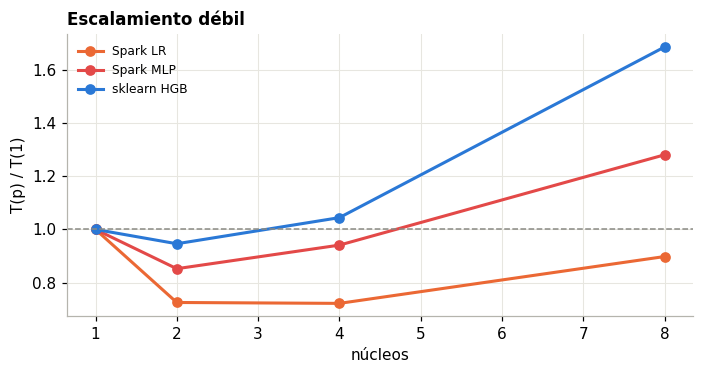

In [7]:
D = B[B.exp == "debil"].copy()
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for (e, m), co, nom in [(("spark", "lr"), C["naranja"], "Spark LR"), (("spark", "mlp"), C["rojo"], "Spark MLP"), (("sk", "hgb"), C["azul"], "sklearn HGB")]:
    d = D[(D.engine == e) & (D.model == m)].sort_values("cores")
    if len(d): ax.plot(d.cores, d.fit / d.fit.iloc[0], marker="o", color=co, label=nom)
ax.axhline(1, color=C["gris"], ls="--", lw=1); ax.set(title="Escalamiento débil", xlabel="núcleos", ylabel="T(p) / T(1)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- **HGB se mantiene casi constante hasta 4 núcleos** (0,95 a 1,04), y con 8 sube a 1,69. Los núcleos de eficiencia y el ancho de
  banda de memoria que comparten los histogramas lo frenan.
- **En Spark, el tiempo con 2 y 4 núcleos es menor que con 1** (0,72 a 0,94). El punto de 1 núcleo está penalizado: procesa en serie
  al menos 8 particiones con un solo slot, y la sobrecarga por tarea e iteración no se reparte. No se aisló la causa exacta. Con 8
  núcleos, la LR queda en 0,90 y el MLP en 1,28.
- **Conclusión:** en una sola máquina, el escalamiento débil es bueno hasta los 4 núcleos de rendimiento. Pasar a 8 cuesta
  eficiencia en todos los modelos, no solo en Spark.

## 7.5 Evidencia de Spark

**Fuente.** Sin `winutils.exe`, Spark no puede escribir el registro de eventos en Windows: Hadoop exige permisos POSIX al crear el
archivo (`Shell.getSetPermissionCommand`). Por eso `05_benchmark.py` guarda, antes de cerrar la sesión, la API REST de la Spark UI
en vivo (`/api/v1/applications/<id>/jobs`, `stages`, `allexecutors` y `sql`). Son los mismos datos que muestran las pestañas Jobs,
Stages, Executors y SQL. El punto medido es el MLP de Spark con 3 millones de filas y 8 núcleos (`results/bench/spark_ui/`), y
`scripts/05b_spark_ui.py` los resume.

,Valor
Jobs,205.0
Etapas ejecutadas,230.0
Etapas saltadas (reusan shuffle o caché),199.0
Tareas,4525.0
Tareas fallidas,0.0
GC de la JVM (s),2.0
Leído del Parquet (GB),21.9
Shuffle escrito (MB),228.1
Caché en memoria (MB),338.6
Caché en disco (MB),6.9


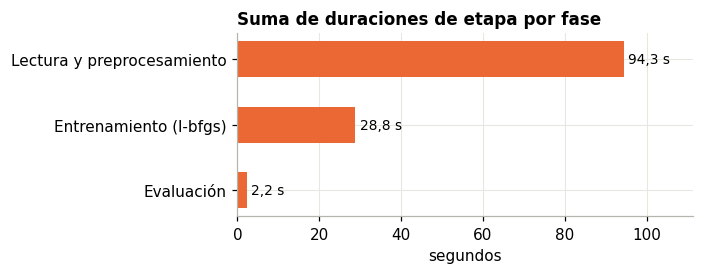

,fase,llamada,etapas,tareas,dur_s,cpu_s,gc_s,shuffle_escr_mb,mem_pico_mb
0,Lectura y preprocesamiento,$anonfun$withThreadLocalCaptured$2 @ Completab...,80,2272,69.8,247.1,6.7,191.7,14552.4
1,Entrenamiento (l-bfgs),treeAggregate @ LBFGS.scala,46,460,26.9,183.8,1.2,4.3,0.2
2,Lectura y preprocesamiento,first @ C,93,1703,20.1,71.2,3.8,24.2,2112.0
3,Lectura y preprocesamiento,count @ NativeMethodAccessorImpl.java,2,24,3.6,20.7,0.3,0.0,12935.4
4,Entrenamiento (l-bfgs),count @ LBFGS.scala,1,16,1.9,10.5,0.4,0.0,0.0
5,Evaluación,map @ BinaryClassificationMetrics.scala,1,8,1.0,5.2,0.0,4.1,28.5


In [8]:
U = pd.read_csv(RES / "bench" / "spark_ui_resumen.csv", index_col=0).valor
G = pd.read_csv(RES / "bench" / "spark_ui_stages.csv")
k = {"jobs": "Jobs", "etapas_completas": "Etapas ejecutadas", "etapas_saltadas": "Etapas saltadas (reusan shuffle o caché)", "tareas": "Tareas",
     "tareas_fallidas": "Tareas fallidas", "gc_s": "GC de la JVM (s)", "entrada_gb": "Leído del Parquet (GB)", "shuffle_escr_mb": "Shuffle escrito (MB)",
     "cache_mem_mb": "Caché en memoria (MB)", "cache_disco_mb": "Caché en disco (MB)", "spill_disco_mb": "Spill a disco (MB)"}
display(U[list(k)].rename(k).round(1).to_frame("Valor"))
f = G.groupby("fase")[["dur_s", "tareas", "cpu_s", "gc_s"]].sum().sort_values("dur_s")
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(f.index, f.dur_s, color=C["naranja"], height=.55)
for i, v in enumerate(f.dur_s): ax.text(v + 1, i, es(v, 1) + " s", va="center", fontsize=9)
ax.set(title="Suma de duraciones de etapa por fase", xlabel="segundos", xlim=(0, f.dur_s.max() * 1.18)); plt.tight_layout(); plt.show()
G[["fase", "llamada", "etapas", "tareas", "dur_s", "cpu_s", "gc_s", "shuffle_escr_mb", "mem_pico_mb"]].head(6).round(1)

Lo que muestra la UI:

- **El entrenamiento son 46 etapas `treeAggregate` de `LBFGS.scala`,** de unos 0,6 s cada una. Las 20 iteraciones evalúan la
  función unas 2,3 veces cada una, por la búsqueda de línea. Cada evaluación recorre las 8 particiones en caché: 339 MB en memoria
  y 7 MB en disco, sin spill. El MLP con frecuencia (`d = 27`) cabe con holgura. Con hashing de 2^12, la misma caché densa
  ocuparía unas 150 veces más (capítulo 5).
- **El preprocesamiento domina:** unos 94 s de etapas y 4.000 de las 4.525 tareas. Spark leyó 21,9 GB del Parquet porque el `Prep`
  recorre la entrada una vez por cada agregación. La entrada no se persiste antes de los conteos, y esa es la optimización más
  directa que queda.
- **Sin fallos y con poco GC:** ninguna tarea falló, no hubo spill y la JVM gastó 2 s en GC. De las 429 etapas, 199 se saltaron
  porque AQE reutilizó resultados de shuffle ya calculados.
- Las duraciones de etapa se suman y pueden solaparse, así que no equivalen al tiempo de pared.

## 7.6 Costo estimado en la nube

Se valora cada corrida medida como si fuera en una instancia de AWS de capacidad parecida: m6i.2xlarge, con 8 vCPU y 32 GiB. Se
usan precios de lista bajo demanda en us-east-1: 0,384 USD por hora, más 0,096 USD por hora de recargo si se usa EMR. Son
precios de referencia y pueden cambiar. Se asume además que esa instancia tarda lo mismo que el equipo de las mediciones.

In [9]:
P_EC2, P_EMR = 0.384, 0.096
k = c.assign(total=c.read + c.prep + c.fit + c.pred, motor=c.engine.map(lambda e: ENG[e][0]))
k["USD EC2"] = k.total / 3600 * P_EC2
k["USD EMR"] = np.where(k.engine == "spark", k.total / 3600 * (P_EC2 + P_EMR), np.nan)
k["USD por millón de filas"] = k["USD EC2"] / (k.n / 1e6)
k[["motor", "model", "n", "total", "USD EC2", "USD EMR", "USD por millón de filas", "auc"]].sort_values(["model", "n", "motor"]).round(4).reset_index(drop=True)

,motor,model,n,total,USD EC2,USD EMR,USD por millón de filas,auc
0,PySpark,lr,100110,56.9660,0.0061,0.0076,0.0607,0.7061
1,scikit-learn,lr,100110,3.1756,0.0003,NaN,0.0034,0.6384
2,PySpark,lr,999123,64.0841,0.0068,0.0085,0.0068,0.7299
3,scikit-learn,lr,999123,20.6380,0.0022,NaN,0.0022,0.6927
4,PySpark,lr,3000326,85.3305,0.0091,0.0114,0.0030,0.7285
5,scikit-learn,lr,3000326,63.5483,0.0068,NaN,0.0023,0.7213
6,PySpark,lr,10003138,162.6282,0.0173,0.0217,0.0017,0.7308
7,scikit-learn,lr,10003138,224.9005,0.0240,NaN,0.0024,0.7296
8,PySpark,mlp,100110,54.4914,0.0058,0.0073,0.0581,0.6071
9,scikit-learn,mlp,100110,4.0571,0.0004,NaN,0.0043,0.6619


- **El costo de cómputo es despreciable en ambos motores:** 3 centavos de dólar o menos por corrida, incluso con 10 millones de
  filas. Con 10 millones, el modelo lineal cuesta 0,017 USD en Spark y 0,024 USD en scikit-learn: la diferencia es la de tiempo.
- **Con pocas filas, Spark cuesta de 13 a 18 veces más,** por su costo fijo: 0,006 USD frente a 0,0003 o 0,0004 USD con
  100 mil filas.
- **Lo que domina en la práctica no aparece en la tabla.** Un clúster de EMR cobra los nodos maestro y de trabajo mientras arranca
  (varios minutos) y mientras está ocioso. Además, el tiempo de las personas para depurar Spark supera con creces el de máquina. En
  este proyecto, sortear `winutils` y el OOM del MLP costó horas.
- **Spark se paga solo** si los datos no caben en una máquina, como Criteo 1TB. Ahí la alternativa no es scikit-learn más lento,
  sino que scikit-learn no corre. Con Avazu en una instancia de 32 GiB, la opción barata es scikit-learn, o la LR de Spark si se
  quiere el ajuste más rápido con todos los datos.